# Passo a passo · Sobreajuste, Ridge, Lasso e modelos generalizados
**Fundamentos de Machine Learning · Aula 6 · Prática guiada · Tempo: 1 hora**

Na aula 5 aprendemos a medir o erro de um modelo em dados que ele não viu. Agora vamos usar essa medida para responder a outra pergunta: **qual é a complexidade certa para um modelo?** Um modelo rígido demais não captura o padrão dos dados (**subajuste**, *underfitting*). Um modelo flexível demais decora os dados de treino e erra nos novos (**sobreajuste**, *overfitting*). A **regularização** (Ridge e Lasso) é a ferramenta que controla essa flexibilidade. No fim, vemos que a mesma ideia vale para a regressão logística e para toda a família dos **modelos lineares generalizados**.

Usamos a base **Auto MPG**, a mesma da atividade da aula 2: cada linha é um modelo de carro dos anos 1970 e início dos 1980, e o alvo é o consumo em milhas por galão (`mpg`; maior = mais econômico).

**Como usar este notebook.** Este é o roteiro da aula, para o professor conduzir com a turma. Execute as células na ordem: antes de cada bloco de código há o que será feito e por quê; depois de cada gráfico, como lê-lo e o que observar. As ilustrações trazem a analogia de cada conceito. As perguntas **Para discutir** são pausas para ouvir a turma antes de seguir; a resposta esperada vem logo abaixo, para apoiar a condução.

| Etapa | Conteúdo | Tempo |
|---|---|---|
| 0 | Bibliotecas e dados | 5 min |
| 1 | Sobreajuste: `PolynomialFeatures` e três modelos | 14 min |
| 2 | Curva de complexidade: treino × validação | 5 min |
| 3 | Ridge: penalizar coeficientes grandes | 11 min |
| 4 | Lasso: penalizar, selecionar features e comparar com o Ridge | 13 min |
| 5 | Modelos lineares generalizados | 9 min |
| 6 | Fechamento | 3 min |

### A aula em uma figura

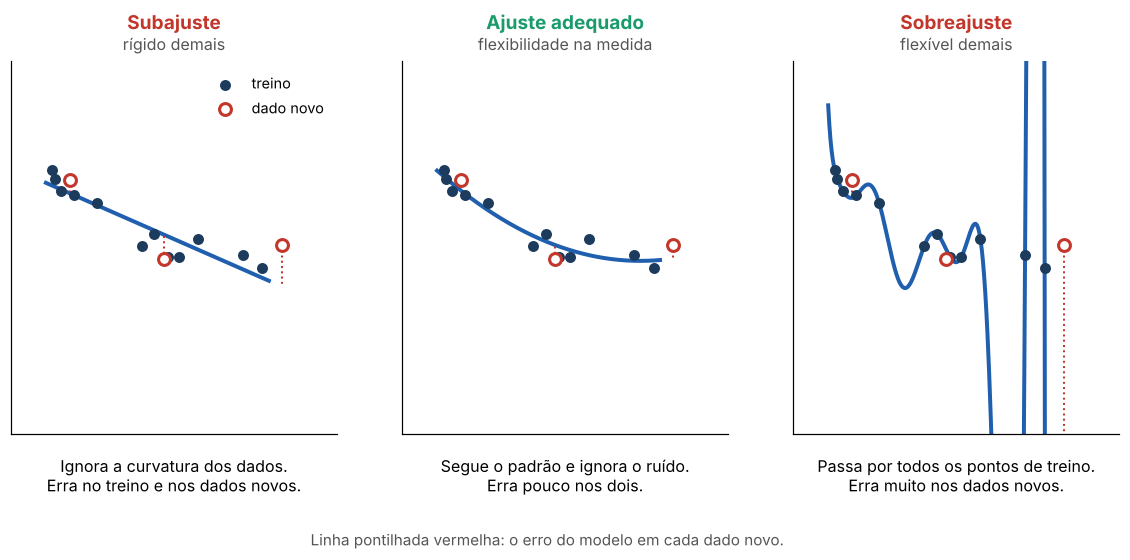

*Três alunos estudando para a mesma prova. O primeiro decorou uma regra simples demais e erra a lista e a prova (**subajuste**). O segundo entendeu o padrão por trás dos exercícios (**ajuste adequado**). O terceiro decorou as respostas da lista: acerta todas as questões que já viu e erra as novas (**sobreajuste**). Nesta aula, a "lista" é o conjunto de treino e a "prova" são carros que o modelo nunca viu.*

---
## Etapa 0 · Bibliotecas e dados (5 min)

Além das bibliotecas das aulas anteriores, vamos usar `PolynomialFeatures`, que cria as potências de uma feature (`x`, `x²`, `x³`, …), e as classes `Ridge` e `Lasso`. A função `rmse` calcula a raiz do erro quadrático médio da aula 5: um **erro típico em mpg**, na mesma unidade do alvo.

In [1]:
import numpy as np                                     # cálculos numéricos
import pandas as pd                                    # leitura e manipulação de tabelas
import matplotlib.pyplot as plt                        # gráficos
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV, LogisticRegression
from sklearn.metrics import mean_squared_error

TREINO, VALID, MODELO, CINZA = '#1d3b5c', '#c2362b', '#1f5fae', '#a3afbc'
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'axes.titleweight': 'bold'})

def rmse(y_real, y_prev):
    """Raiz do erro quadrático médio: erro típico, em mpg."""
    return np.sqrt(mean_squared_error(y_real, y_prev))

**Passo 0.1 · Ler os dados.** Lemos o arquivo `auto-mpg.csv` da pasta `data` do repositório. Em `horsepower`, os valores ausentes aparecem como `'?'`: o parâmetro `na_values='?'` os converte em `NaN`, e removemos esses 6 carros.

In [2]:
df = pd.read_csv('../../data/auto-mpg.csv', na_values='?')
df = df.dropna(subset=['horsepower'])
print(f'{len(df)} carros')
df.head()

392 carros


,car_name,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,mpg
0,"chevrolet,chevelle,malibu",8,307.0,130.0,3504,12.0,70,1,18.0
1,"buick,skylark,320",8,350.0,165.0,3693,11.5,70,1,15.0
2,"plymouth,satellite",8,318.0,150.0,3436,11.0,70,1,18.0
3,"amc,rebel,sst",8,304.0,150.0,3433,12.0,70,1,16.0
4,"ford,torino",8,302.0,140.0,3449,10.5,70,1,17.0


**Passo 0.2 · Separar o teste.** Separamos 20% dos carros para **teste**, com `random_state=42`. O teste fica guardado até o fim da Etapa 4: ele é a prova final e não é usado para tomar nenhuma decisão.

In [3]:
treino, teste = train_test_split(df, test_size=0.2, random_state=42)
print(f'treino: {len(treino)} carros | teste: {len(teste)} carros')

treino: 313 carros | teste: 79 carros


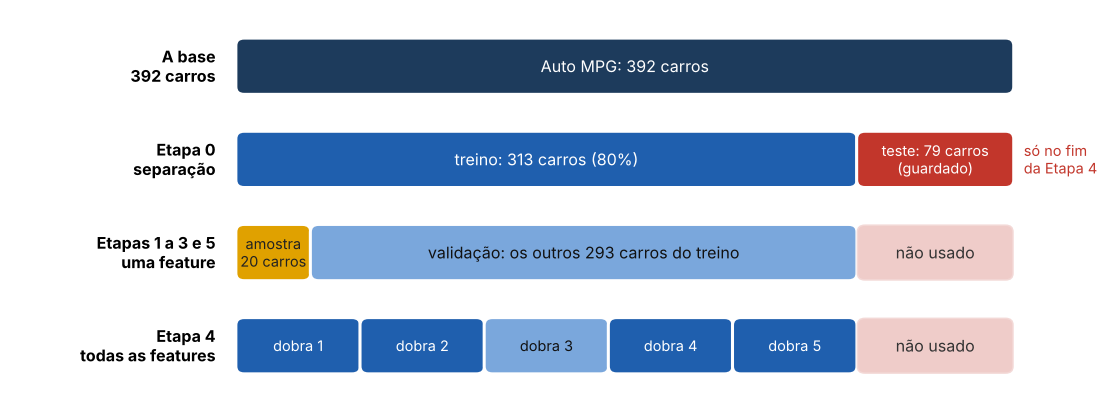

*Como os 392 carros são usados ao longo da aula. O teste é como o envelope lacrado da prova final: só é aberto no fim da Etapa 4. Nas etapas 1, 2, 3 e 5 treinamos com uma amostra pequena de 20 carros e conferimos o erro nos outros 293 do treino. Na Etapa 4 usamos o treino inteiro com validação cruzada, como na aula 5.*

### A relação que vamos modelar

Nas etapas 1 a 4 usamos uma única feature, a potência do motor (`horsepower`), para enxergar as curvas dos modelos.

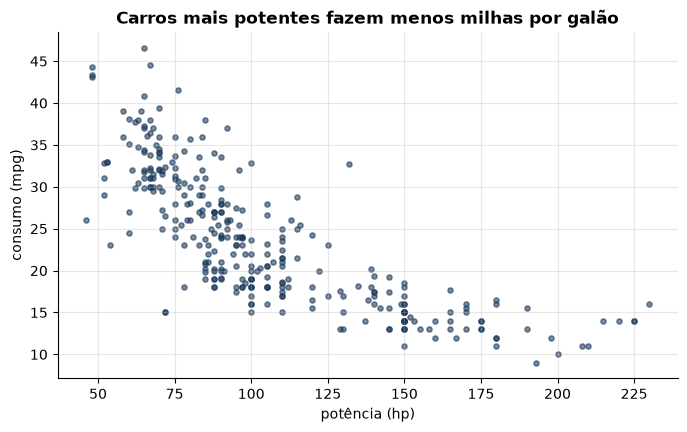

In [4]:
plt.figure(figsize=(8, 4.5))
plt.scatter(treino['horsepower'], treino['mpg'], s=14, color=TREINO, alpha=0.6)
plt.xlabel('potência (hp)')
plt.ylabel('consumo (mpg)')
plt.title('Carros mais potentes fazem menos milhas por galão')
plt.show()

**O que observar.** A tendência é de queda, mas **não é uma reta**: a queda é forte entre 50 e 120 hp e fica mais suave depois. Guarde essa curvatura; ela é a chave da Etapa 1.

---
## Etapa 1 · Sobreajuste: uma feature, três modelos (14 min)

Para tornar o sobreajuste visível, imagine que só temos **20 carros** para treinar, uma amostra pequena. Os outros 293 carros do treino servem de **validação**: medimos neles o erro em carros que o modelo não viu, sem tocar no teste.

Vamos comparar três polinômios em `horsepower`:

- **grau 1**: a reta da aula 2;
- **grau 2**: `hp` e `hp²`, uma curva simples;
- **grau 12**: `hp`, `hp²`, …, `hp¹²`, uma curva muito flexível.

A função `polinomio(grau)` monta o pipeline em quatro passos:

1. `StandardScaler`: padroniza a potência (média 0, desvio padrão 1). Sem isso, `hp¹²` para um carro de 230 hp seria um número com 29 dígitos, e as contas ficariam instáveis;
2. `PolynomialFeatures`: cria as potências da potência padronizada;
3. `StandardScaler`: padroniza cada potência, como na aula 4, para que todas fiquem em escalas parecidas;
4. o regressor: `LinearRegression` por padrão.

Mesmo com `hp¹²`, o modelo continua sendo uma regressão linear: os coeficientes entram de forma linear, só as features foram transformadas.

### Passo 1.0 · Como o `PolynomialFeatures` funciona

Antes de treinar, vale ver o que o `PolynomialFeatures` faz com os dados. Pegamos três carros do treino, de pouca, média e muita potência, e pedimos as potências de `hp` até o grau 3.

In [5]:
idx_ex = [(treino['horsepower'] - h).abs().idxmin() for h in [65, 110, 165]]
tres_carros = treino.loc[idx_ex, ['car_name', 'horsepower']]
nomes_ex = tres_carros['car_name'].str.replace(',', ' ').values

poli3 = PolynomialFeatures(degree=3, include_bias=False)   # include_bias=False: sem a coluna de 1s
matriz = poli3.fit_transform(tres_carros[['horsepower']].to_numpy())   # .to_numpy(): para darmos nomes curtos às colunas
pd.DataFrame(matriz, columns=poli3.get_feature_names_out(['hp']), index=nomes_ex).astype(int)

,hp,hp^2,hp^3
ford escort 4w,65,4225,274625
dodge aspen,110,12100,1331000
chevrolet impala,165,27225,4492125


**O que observar.** Cada linha continua sendo um carro, mas a única coluna `hp` virou três: `hp`, `hp^2` e `hp^3`. O modelo de grau 3 é a regressão linear da aula 2 aplicada a essas três colunas:

$$\widehat{mpg} = a + b_1 \cdot hp + b_2 \cdot hp^2 + b_3 \cdot hp^3$$

É isso que significa "continua linear": o modelo só soma colunas multiplicadas por coeficientes. A curvatura vem das colunas novas.

**Por que padronizar antes.** Repare como os números crescem rápido. Veja o que aconteceria no grau 12:

In [6]:
for hp in [65, 230]:
    print(f'{hp} hp elevado a 12 = {hp ** 12:.1e}  ({len(str(hp ** 12))} dígitos)')

z_ex = StandardScaler().fit(treino[['horsepower']]).transform(tres_carros[['horsepower']])
poli12 = PolynomialFeatures(degree=12, include_bias=False).fit_transform(z_ex)
print('\nDepois de padronizar a potência, o maior valor de z^12 entre os três carros:', f'{np.abs(poli12[:, -1]).max():.1f}')

65 hp elevado a 12 = 5.7e+21  (22 dígitos)
230 hp elevado a 12 = 2.2e+28  (29 dígitos)

Depois de padronizar a potência, o maior valor de z^12 entre os três carros: 242.7


Sem padronização, as colunas teriam escalas que vão de dezenas a 10²⁸, e as contas do ajuste ficariam instáveis. Por isso o pipeline padroniza a potência **antes** do `PolynomialFeatures` e padroniza cada coluna nova **depois**.

### Cada coluna nova é uma curva

O gráfico mostra, para todas as potências de 45 a 235 hp, as três colunas criadas (já padronizadas). Cada uma tem uma forma diferente: `hp` é uma reta, `hp²` é uma parábola e `hp³` tem uma "dobra". O ajuste escolhe **quanto de cada curva somar**, e a soma é a curva final do modelo.

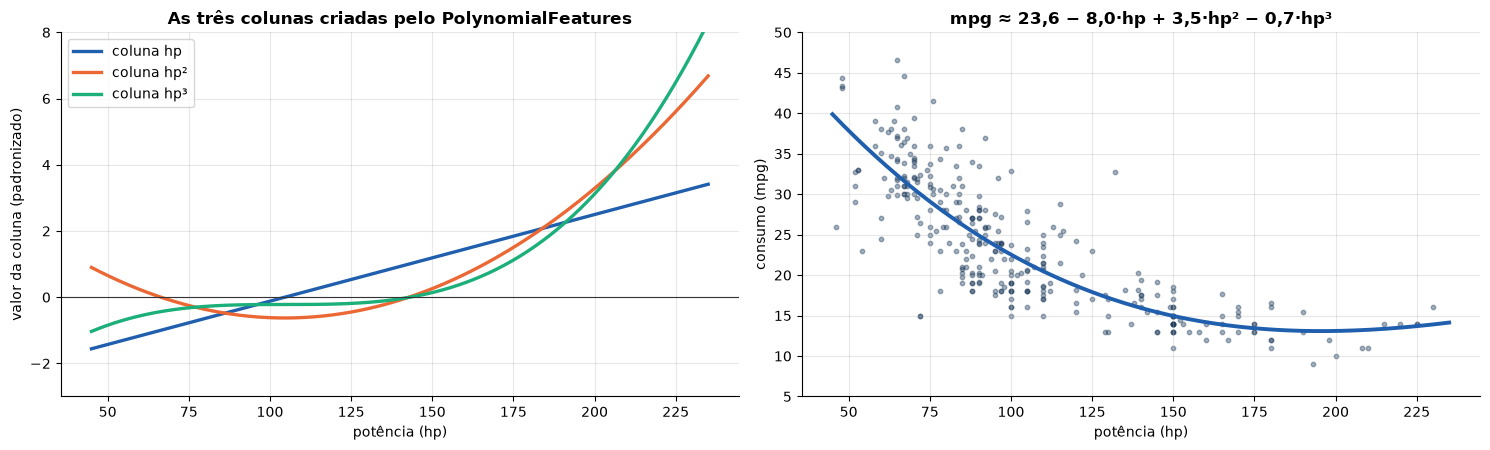

In [7]:
faixa_hp = pd.DataFrame({'horsepower': np.linspace(45, 235, 400)})
pipe_base = make_pipeline(StandardScaler(), PolynomialFeatures(3, include_bias=False), StandardScaler())
pipe_base.fit(treino[['horsepower']])
colunas = pipe_base.transform(faixa_hp)
modelo3 = make_pipeline(StandardScaler(), PolynomialFeatures(3, include_bias=False), StandardScaler(),
                        LinearRegression()).fit(treino[['horsepower']], treino['mpg'])
b = modelo3[-1].coef_

fig, eixos = plt.subplots(1, 2, figsize=(15, 4.6))
for k, (cor, nome) in enumerate(zip([MODELO, '#eb6834', '#1baf7a'], ['hp', 'hp²', 'hp³'])):
    eixos[0].plot(faixa_hp['horsepower'], colunas[:, k], color=cor, lw=2.4, label=f'coluna {nome}')
eixos[0].axhline(0, color='#333', lw=0.8)
eixos[0].set_ylim(-3, 8)
eixos[0].set_xlabel('potência (hp)'); eixos[0].set_ylabel('valor da coluna (padronizado)')
eixos[0].set_title('As três colunas criadas pelo PolynomialFeatures')
eixos[0].legend()
eixos[1].scatter(treino['horsepower'], treino['mpg'], s=10, color=TREINO, alpha=0.4)
eixos[1].plot(faixa_hp['horsepower'], modelo3.predict(faixa_hp), color=MODELO, lw=2.8)
eixos[1].set_ylim(5, 50)
eixos[1].set_xlabel('potência (hp)'); eixos[1].set_ylabel('consumo (mpg)')
termos = ''.join(f" {'+' if v >= 0 else '−'} {abs(v):.1f}·{n}" for v, n in zip(b, ['hp', 'hp²', 'hp³']))
eixos[1].set_title(f'mpg ≈ {modelo3[-1].intercept_:.1f}{termos}'.replace('.', ','))
plt.tight_layout()
plt.show()

**Como ler o gráfico.** À esquerda, as colunas que o `PolynomialFeatures` criou, uma curva por coluna. À direita, o modelo de grau 3 treinado nos 313 carros: o título traz a conta que ele faz, com os coeficientes aprendidos (em colunas padronizadas).

**O que observar.** O modelo final é uma mistura das curvas da esquerda, com os pesos do título. Com grau 12, haveria 12 curvas para misturar, cada uma mais ondulada que a anterior, e é dessa liberdade que vem o sobreajuste que veremos a seguir.

**Com mais de uma feature.** O `PolynomialFeatures` também multiplica features entre si. Com potência e peso e grau 2, ele cria:

In [8]:
poli_2f = PolynomialFeatures(degree=2, include_bias=False)
duas = treino.loc[idx_ex, ['horsepower', 'weight']]
pd.DataFrame(poli_2f.fit_transform(duas.to_numpy()), columns=poli_2f.get_feature_names_out(['hp', 'weight']), index=nomes_ex).astype(int)

,hp,weight,hp^2,hp weight,weight^2
ford escort 4w,65,2045,4225,132925,4182025
dodge aspen,110,3620,12100,398200,13104400
chevrolet impala,165,4209,27225,694485,17715681


A coluna `hp weight` é o produto das duas: uma **interação**, que permite ao modelo capturar efeitos combinados, como "potência pesa mais no consumo de carros pesados". Na Etapa 4, aplicamos o grau 4 às 6 features da base, e as combinações chegam a 209 colunas.

In [9]:
def fmt(v):
    """Formata um erro para os títulos dos gráficos (padrão brasileiro)."""
    if v >= 1e6:
        return f'{v / 1e6:.1f} milhões'.replace('.', ',')
    if v >= 1000:
        return f'{v:,.0f}'.replace(',', '.')
    return f'{v:.1f}'.replace('.', ',')

In [10]:
rng = np.random.default_rng(0)
idx = rng.choice(len(treino), size=20, replace=False)
amostra = treino.iloc[idx]                     # 20 carros para treinar
validacao = treino.drop(treino.index[idx])     # 293 carros para validar

X_am, y_am = amostra[['horsepower']], amostra['mpg']
X_val, y_val = validacao[['horsepower']], validacao['mpg']
grade = pd.DataFrame({'horsepower': np.linspace(45, 235, 400)})   # pontos para desenhar as curvas

**Passo 1.1 · Treinar os três modelos.** Treinamos cada polinômio na amostra de 20 carros e calculamos o RMSE na própria amostra (treino) e nos 293 carros de validação.

In [11]:
def polinomio(grau, regressor=None):
    """Pipeline: potências de grau 1 até `grau` -> padronização -> regressor (LinearRegression por padrão)."""
    regressor = regressor if regressor is not None else LinearRegression()
    return make_pipeline(StandardScaler(), PolynomialFeatures(grau, include_bias=False),
                         StandardScaler(), regressor)

resultados = {}
for grau in [1, 2, 12]:
    modelo = polinomio(grau).fit(X_am, y_am)
    resultados[grau] = {'modelo': modelo,
                        'treino': rmse(y_am, modelo.predict(X_am)),
                        'validacao': rmse(y_val, modelo.predict(X_val))}
    print(f"grau {grau:2d}: RMSE treino {resultados[grau]['treino']:6.2f} | validação {resultados[grau]['validacao']:10.2f}")

grau  1: RMSE treino   4.20 | validação       6.17
grau  2: RMSE treino   2.91 | validação       5.21
grau 12: RMSE treino   2.33 | validação 2246046.84


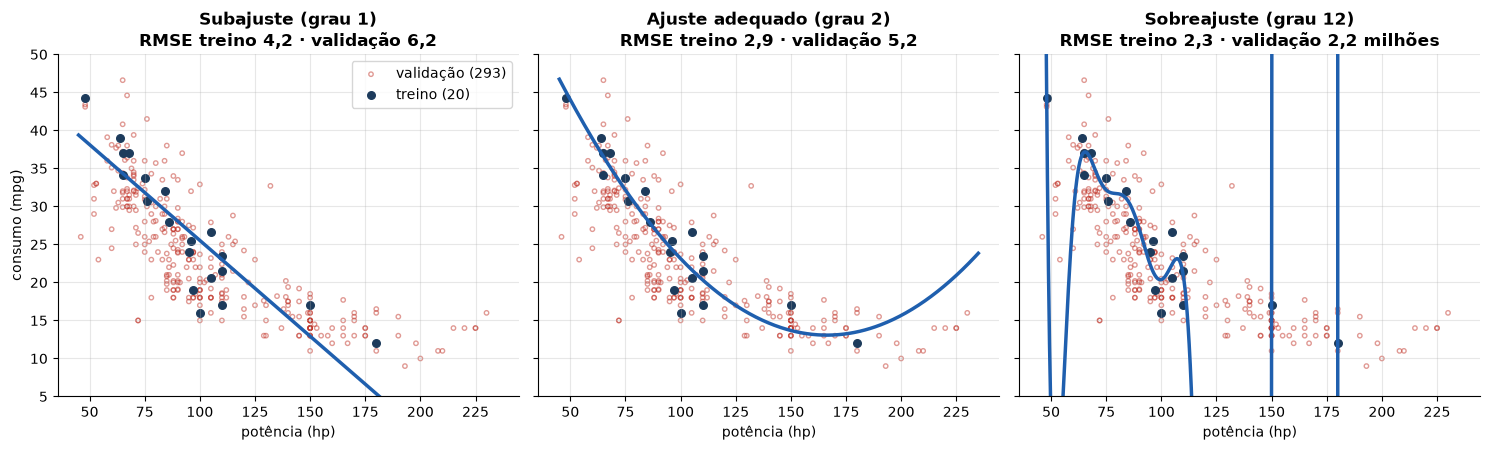

In [12]:
titulos = {1: 'Subajuste (grau 1)', 2: 'Ajuste adequado (grau 2)', 12: 'Sobreajuste (grau 12)'}
fig, eixos = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for eixo, grau in zip(eixos, [1, 2, 12]):
    r = resultados[grau]
    eixo.scatter(X_val['horsepower'], y_val, s=10, facecolors='none', edgecolors=VALID, alpha=0.5, label='validação (293)')
    eixo.scatter(X_am['horsepower'], y_am, s=30, color=TREINO, label='treino (20)')
    eixo.plot(grade['horsepower'], r['modelo'].predict(grade), color=MODELO, lw=2.5)
    eixo.set_ylim(5, 50)
    eixo.set_title(f"{titulos[grau]}\nRMSE treino {fmt(r['treino'])} · validação {fmt(r['validacao'])}")
    eixo.set_xlabel('potência (hp)')
eixos[0].set_ylabel('consumo (mpg)')
eixos[0].legend(loc='upper right')
plt.tight_layout()
plt.show()

**Como ler o gráfico.** Pontos cheios: os 20 carros de treino. Círculos vazados: os 293 de validação. Linha azul: o modelo. O título traz os dois erros, em mpg.

**O que observar.**

- **Grau 1 (subajuste):** a reta não acompanha a curvatura. Erra nos carros de pouca e de muita potência, **no treino e na validação**. O modelo é rígido demais para o padrão dos dados.
- **Grau 2 (ajuste adequado):** a curva acompanha a tendência. O erro de validação é o menor dos três.
- **Grau 12 (sobreajuste):** o menor erro de treino, mas a curva faz oscilações para passar perto de cada um dos 20 carros e dispara fora deles. O erro de validação chega a milhões de mpg, um valor sem sentido físico: o modelo **decorou** a amostra e não sabe nada sobre carros fora dela.

### Um exemplo concreto: três carros que o modelo não viu

Erros médios escondem o que acontece em cada caso. Vamos pegar três carros da validação, um de pouca, um de média e um de muita potência, e comparar o consumo real com o que cada modelo prevê.

In [13]:
potencias_alvo = [65, 110, 165]
exemplos = validacao.loc[[(validacao['horsepower'] - h).abs().idxmin() for h in potencias_alvo]]
tabela_ex = pd.DataFrame({'carro': exemplos['car_name'].str.replace(',', ' '),
                          'potência (hp)': exemplos['horsepower'],
                          'mpg real': exemplos['mpg']})
for grau in [1, 2, 12]:
    tabela_ex[f'previsto grau {grau}'] = resultados[grau]['modelo'].predict(exemplos[['horsepower']]).round(1)
tabela_ex.reset_index(drop=True)

,carro,potência (hp),mpg real,previsto grau 1,previsto grau 2,previsto grau 12
0,ford escort 4w,65.0,34.4,34.3,36.6,37.1
1,dodge aspen,110.0,18.6,23.0,20.3,20.8
2,chevrolet impala,165.0,14.0,9.1,13.1,12140.9


**O que observar.**

- **Grau 1:** acerta o Ford Escort, mas superestima o Dodge Aspen (23,0 contra 18,6 mpg) e subestima o Chevrolet Impala (9,1 contra 14,0 mpg). A reta não consegue dobrar junto com os dados: o erro vem da **forma** do modelo, e se repete em qualquer carro de potência média ou alta.
- **Grau 2:** as três previsões ficam a no máximo 2,2 mpg do valor real.
- **Grau 12:** nos dois primeiros carros, a previsão é parecida com a do grau 2. No Chevrolet Impala, o modelo prevê mais de 12 mil milhas por galão. O Impala caiu num trecho em que a curva dispara, e o modelo não tem como saber que a previsão é absurda: ele só aprendeu a passar perto dos 20 carros que viu.

### Como diagnosticar

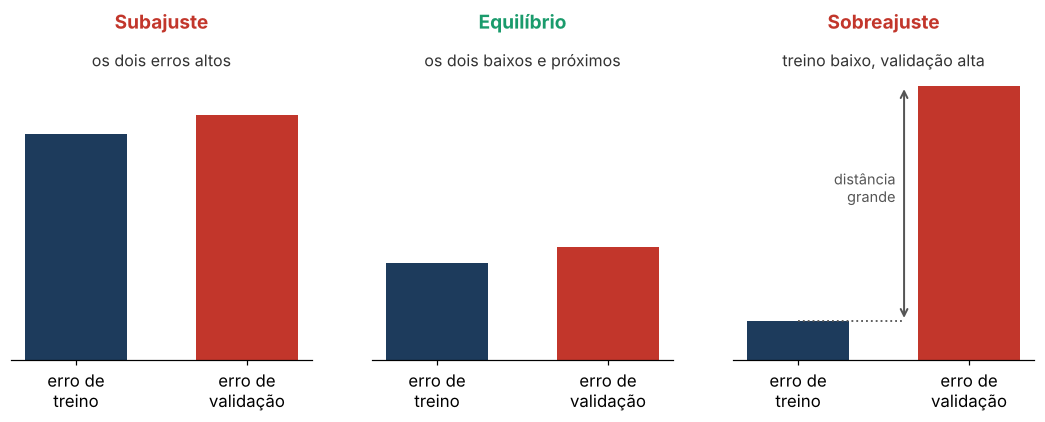

*A regra de diagnóstico compara os dois erros. **Os dois altos:** subajuste, o modelo não aprendeu nem o que viu. **Os dois baixos e próximos:** equilíbrio. **Treino baixo e validação alta:** sobreajuste, o modelo decorou o que viu. Como num exame de direção: quem erra no percurso treinado e no percurso novo não aprendeu a dirigir; quem só acerta o percurso treinado decorou o caminho.*

**Para discutir.** Se tivéssemos 300 carros de treino em vez de 20, você espera que o polinômio de grau 12 sobreajuste mais ou menos? Por quê?

---
## Etapa 2 · Curva de complexidade: treino × validação (5 min)

Um único sorteio de 20 carros pode enganar. Vamos repetir o experimento com **50 amostras diferentes** e, para cada grau de 1 a 12, guardar a **mediana** dos erros (o valor do meio, que não é distorcido por uma amostra extrema).

Para cada grau e cada amostra, treinamos o polinômio nos 20 carros sorteados (`S`) e medimos o erro neles (treino) e nos carros restantes do treino (`V`, validação).

In [14]:
graus = list(range(1, 13))
mediana_treino, mediana_val = [], []
for grau in graus:
    erros_tr, erros_val = [], []
    for semente in range(50):
        ii = np.random.default_rng(semente).choice(len(treino), 20, replace=False)
        S, V = treino.iloc[ii], treino.drop(treino.index[ii])
        modelo = polinomio(grau).fit(S[['horsepower']], S['mpg'])
        erros_tr.append(rmse(S['mpg'], modelo.predict(S[['horsepower']])))
        erros_val.append(rmse(V['mpg'], modelo.predict(V[['horsepower']])))
    mediana_treino.append(np.median(erros_tr))
    mediana_val.append(np.median(erros_val))

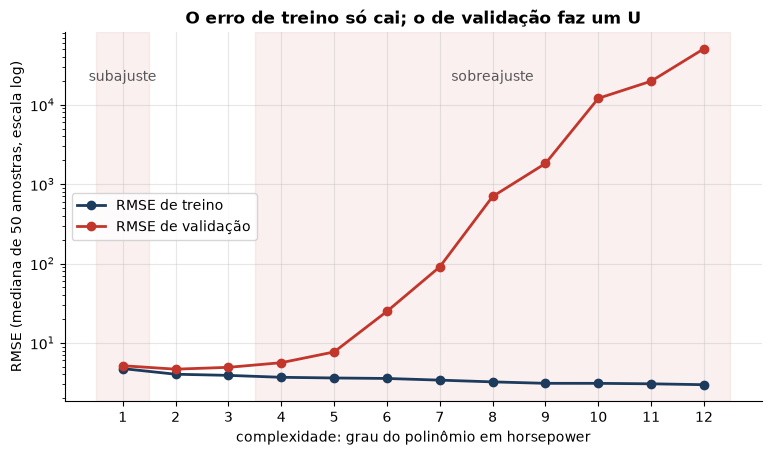

In [15]:
plt.figure(figsize=(9, 4.8))
plt.plot(graus, mediana_treino, 'o-', color=TREINO, lw=2, label='RMSE de treino')
plt.plot(graus, mediana_val, 'o-', color=VALID, lw=2, label='RMSE de validação')
plt.yscale('log')
plt.axvspan(0.5, 1.5, color=VALID, alpha=0.07)
plt.axvspan(3.5, 12.5, color=VALID, alpha=0.07)
plt.text(1, 2e4, 'subajuste', ha='center', color='#555')
plt.text(8, 2e4, 'sobreajuste', ha='center', color='#555')
plt.xticks(graus)
plt.xlabel('complexidade: grau do polinômio em horsepower')
plt.ylabel('RMSE (mediana de 50 amostras, escala log)')
plt.title('O erro de treino só cai; o de validação faz um U')
plt.legend(loc='center left')
plt.show()

**Como ler o gráfico.** O eixo y está em **escala logarítmica**: cada linha de grade vale 10 vezes a anterior. Sem ela, a parte esquerda do gráfico seria uma linha colada no zero.

**O que observar.** O erro de treino **só diminui**: um polinômio de grau maior contém os de grau menor como caso particular, então sempre consegue se aproximar mais dos pontos que viu. O erro de validação cai do grau 1 para o grau 2, volta a subir a partir do grau 3 e dispara depois do grau 5. A complexidade certa fica no **fundo do U**.

**Para discutir.** Escolher o grau é uma forma de controlar a complexidade, mas em degraus: grau 2 ou grau 3, sem meio-termo. Seria possível usar um polinômio de grau alto e, mesmo assim, evitar as oscilações? Guarde a pergunta para a Etapa 3.

---
## Etapa 3 · Ridge: penalizar coeficientes grandes (11 min)

O sobreajuste do grau 12 aparece como **coeficientes grandes**, positivos e negativos, que se cancelam nos 20 carros de treino e explodem fora deles. A regularização muda o custo que o modelo minimiza: além do erro, ele passa a **pagar pelo tamanho dos coeficientes**.

Antes de regularizar, vamos confirmar o sintoma: compare os coeficientes dos modelos de grau 2 e de grau 12 da Etapa 1.

In [16]:
coef_g2 = resultados[2]['modelo'][-1].coef_
coef_g12 = resultados[12]['modelo'][-1].coef_
print('grau 2 :', np.round(coef_g2, 1))
print('grau 12:', np.round(coef_g12).astype(int))
print(f'\nmaior |coeficiente|  grau 2: {np.abs(coef_g2).max():.1f}   grau 12: {np.abs(coef_g12).max():,.0f}')

grau 2 : [-9.8  3.8]
grau 12: [   -25     84    841  -1318 -17332 -14527  54047  39679 -33693  20007
 -39847  -7999]

maior |coeficiente|  grau 2: 9.8   grau 12: 54,047


**O que observar.** No grau 2, os coeficientes têm o tamanho de poucas milhas por galão. No grau 12, eles chegam a milhares, com sinais alternados: um termo empurra a previsão para cima, o seguinte puxa para baixo, e os dois quase se anulam nos 20 carros de treino. Fora deles, o cancelamento falha e a previsão dispara. **Coeficientes enormes são a assinatura do sobreajuste.**

**Ridge (penalidade L2):**

$$J(b) = \sum_i (y_i - \hat y_i)^2 + \alpha \sum_j b_j^2$$

- `α = 0`: a regressão sem penalidade da aula 2.
- `α` grande: todos os coeficientes são puxados para perto de zero, e o modelo fica mais simples.

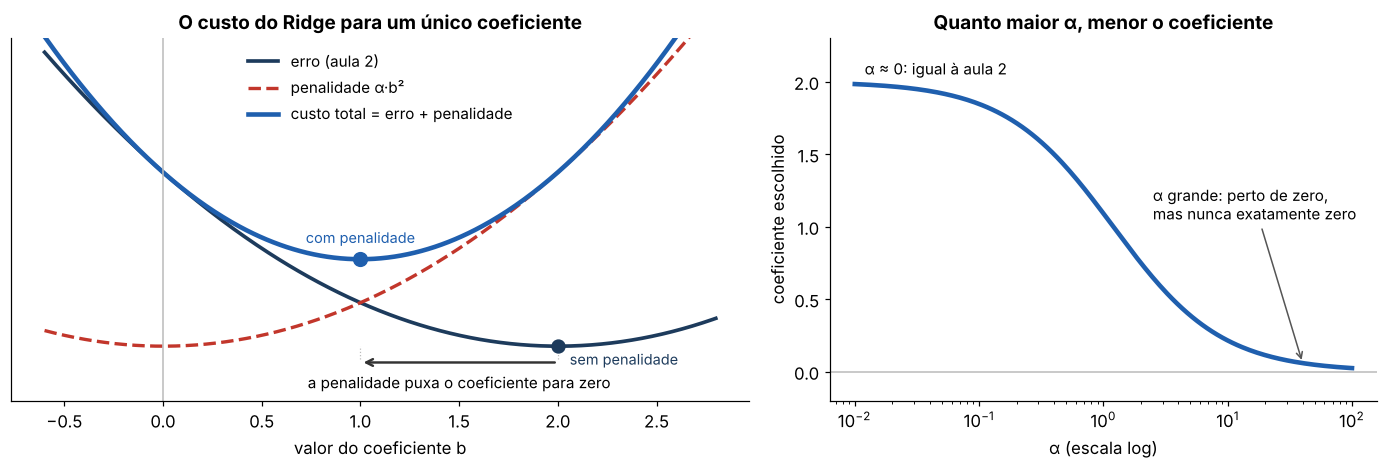

*Para um único coeficiente: a curva escura é o erro da aula 2, com mínimo no valor sem penalidade. A curva tracejada é a penalidade, mínima em zero. O modelo minimiza a soma (azul), e o mínimo da soma fica entre os dois: **a penalidade puxa o coeficiente em direção a zero**. À direita, quanto maior `α`, mais forte o puxão; o coeficiente se aproxima de zero, mas o Ridge nunca o leva exatamente a zero.*

A padronização dentro do pipeline é essencial aqui: a penalidade compara coeficientes de features diferentes, e o tamanho de um coeficiente depende da unidade da feature (aula 4).

**Analogia.** Uma mola presa a cada coeficiente, puxando-o para zero. `α` é a dureza da mola: o modelo só usa um peso grande se ele reduzir muito o erro.

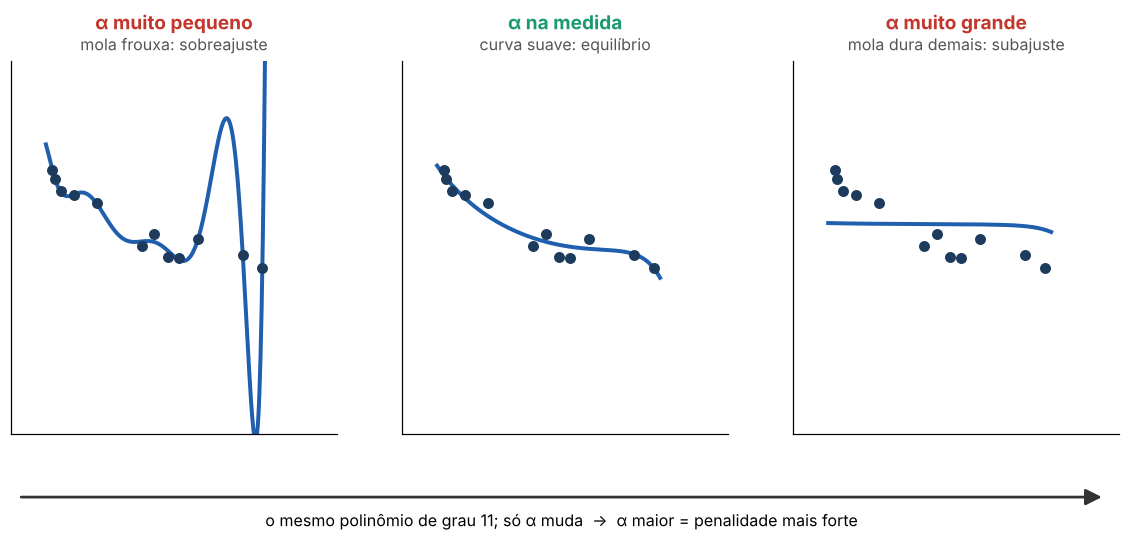

*O mesmo polinômio com três valores de `α`, em dados de exemplo. `α` funciona como um botão de complexidade: girando para a esquerda, o modelo fica flexível demais; para a direita, rígido demais. Em vez de escolher entre graus (degraus), ajustamos `α` de forma contínua. O Passo 3.1 procura a posição certa do botão para os carros.*

### Passo 3.1 · Procurar o melhor α

Para cada `α`, treinamos o polinômio de grau 12 com `Ridge(alpha=a)` como regressor. Como na Etapa 2, repetimos o treino em 50 amostras de 20 carros e guardamos a mediana do erro de validação.

In [17]:
alphas = np.logspace(-4, 3, 22)           # de 0,0001 a 1000, em escala logarítmica
val_ridge = []
for a in alphas:
    erros = []
    for semente in range(50):
        ii = np.random.default_rng(semente).choice(len(treino), 20, replace=False)
        S, V = treino.iloc[ii], treino.drop(treino.index[ii])
        modelo = polinomio(12, Ridge(alpha=a)).fit(S[['horsepower']], S['mpg'])
        erros.append(rmse(V['mpg'], modelo.predict(V[['horsepower']])))
    val_ridge.append(np.median(erros))
melhor_alpha = alphas[int(np.argmin(val_ridge))]
print(f'grau 12 sem penalidade: RMSE de validação {mediana_val[11]:,.1f}')
print(f'grau 12 com Ridge     : RMSE de validação {min(val_ridge):.2f} (α ≈ {melhor_alpha:.2g})')
print(f'grau 2 sem penalidade : RMSE de validação {mediana_val[1]:.2f}')

grau 12 sem penalidade: RMSE de validação 50,900.1
grau 12 com Ridge     : RMSE de validação 5.14 (α ≈ 2.2)
grau 2 sem penalidade : RMSE de validação 4.66


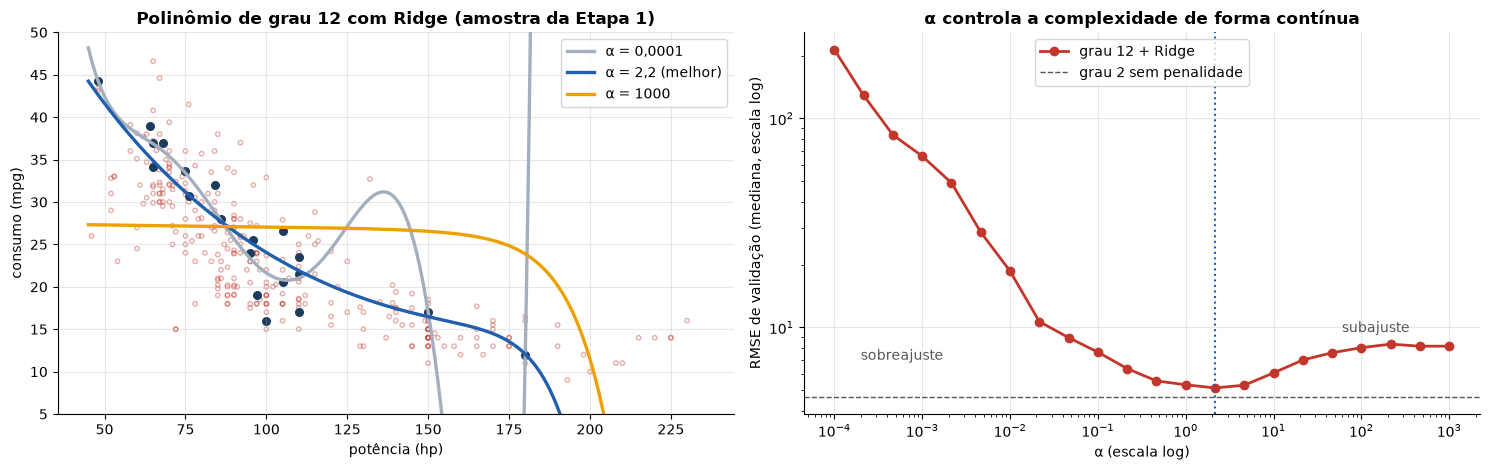

In [18]:
fig, eixos = plt.subplots(1, 2, figsize=(15, 4.8))
# esquerda: a amostra da Etapa 1 com alguns valores de alpha
for a, cor, rotulo in [(1e-4, CINZA, 'α = 0,0001'), (melhor_alpha, MODELO, f'α = {melhor_alpha:.2g} (melhor)'.replace('.', ',')),
                       (1e3, '#eda100', 'α = 1000')]:
    m = polinomio(12, Ridge(alpha=a)).fit(X_am, y_am)
    eixos[0].plot(grade['horsepower'], m.predict(grade), color=cor, lw=2.4, label=rotulo)
eixos[0].scatter(X_val['horsepower'], y_val, s=10, facecolors='none', edgecolors=VALID, alpha=0.4)
eixos[0].scatter(X_am['horsepower'], y_am, s=30, color=TREINO)
eixos[0].set_ylim(5, 50)
eixos[0].set_xlabel('potência (hp)'); eixos[0].set_ylabel('consumo (mpg)')
eixos[0].set_title('Polinômio de grau 12 com Ridge (amostra da Etapa 1)')
eixos[0].legend()
# direita: erro de validação em função de alpha
eixos[1].semilogx(alphas, val_ridge, 'o-', color=VALID, lw=2, label='grau 12 + Ridge')
eixos[1].axhline(mediana_val[1], color='#555', ls='--', lw=1, label='grau 2 sem penalidade')
eixos[1].axvline(melhor_alpha, color=MODELO, ls=':', lw=1.5)
eixos[1].set_yscale('log')
eixos[1].text(2e-4, 7, 'sobreajuste', color='#555'); eixos[1].text(60, 9.5, 'subajuste', color='#555')
eixos[1].set_xlabel('α (escala log)'); eixos[1].set_ylabel('RMSE de validação (mediana, escala log)')
eixos[1].set_title('α controla a complexidade de forma contínua')
eixos[1].legend(loc='upper center')
plt.tight_layout()
plt.show()

**Como ler os gráficos.** À esquerda, o mesmo polinômio de grau 12 treinado na amostra da Etapa 1 com três valores de `α`. À direita, a mediana do erro de validação para cada `α`, com a referência do grau 2 sem penalidade (linha tracejada).

**O que observar.**

- Com `α` muito pequeno (cinza), a curva ainda oscila e dispara: sobreajuste.
- Com o melhor `α` (azul), a curva fica suave e parecida com a do grau 2 na faixa em que há carros de treino, **embora o modelo continue tendo 12 coeficientes**. O erro de validação cai de dezenas de milhares de mpg para perto do erro do grau 2. Acima de 180 hp, fora da faixa dos 20 carros, a curva ainda se afasta dos dados: nenhum modelo tem informação sobre uma região que não viu.
- Com `α` muito grande (amarelo), a mola é dura demais: a curva achata e o modelo volta a subajustar.

O gráfico da direita é a curva em U da Etapa 2, agora com `α` no lugar do grau. **Regularizar é controlar a complexidade com um botão contínuo, em vez de trocar o modelo.**

Atenção: escolhemos `α` olhando a **validação**, e não o teste. É a mesma regra da aula 5.

### Passo 3.2 · O que a penalidade fez com os coeficientes

Treinamos de novo o grau 12 na amostra da Etapa 1, sem penalidade e com o melhor `α`, e comparamos o tamanho dos 12 coeficientes.

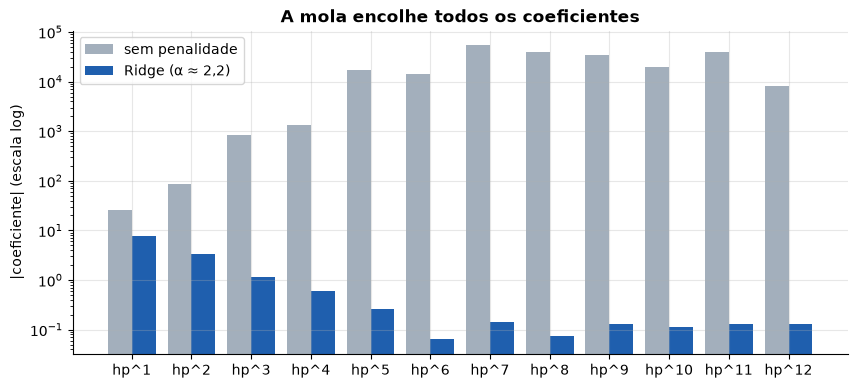

maior |coeficiente|: sem penalidade 54,047 | com Ridge 7.6


In [19]:
sem = polinomio(12).fit(X_am, y_am)[-1].coef_
com = polinomio(12, Ridge(alpha=melhor_alpha)).fit(X_am, y_am)[-1].coef_
pot = np.arange(1, 13)
plt.figure(figsize=(10, 4.2))
plt.bar(pot - 0.2, np.abs(sem), 0.4, color=CINZA, label='sem penalidade')
plt.bar(pot + 0.2, np.abs(com), 0.4, color=MODELO, label=f'Ridge (α ≈ {melhor_alpha:.2g})'.replace('.', ','))
plt.yscale('log')
plt.xticks(pot, [f'hp^{k}' for k in pot])
plt.ylabel('|coeficiente| (escala log)')
plt.title('A mola encolhe todos os coeficientes')
plt.legend()
plt.show()
print(f'maior |coeficiente|: sem penalidade {np.abs(sem).max():,.0f} | com Ridge {np.abs(com).max():.1f}')

**Como ler o gráfico.** Cada par de barras é o tamanho de um coeficiente: o da potência `hp`, o de `hp²` e assim por diante. O eixo y está em escala log: cada linha de grade vale 10 vezes a anterior.

**O que observar.** Sem penalidade, os coeficientes chegam a dezenas de milhares. Com Ridge, o maior cai para menos de 10, a mesma ordem dos coeficientes do grau 2, e as potências mais altas ficam com peso perto de 0,1: o modelo passa a se apoiar nas potências baixas, como faria um polinômio de grau 2. Nenhum coeficiente foi zerado: o Ridge encolhe, mas não elimina.

**Para discutir.** No gráfico da direita do Passo 3.1, onde está o subajuste e onde está o sobreajuste? Por que um `α` muito grande também é ruim?

---
## Etapa 4 · Lasso: penalizar e selecionar features (13 min)

Agora usamos todos os 313 carros de treino e 6 features numéricas. Para dar flexibilidade ao modelo, criamos todas as combinações de **grau até 4**: quadrados (`weight²`), produtos (`weight·model_year`) e assim por diante. As 6 features viram **209**, para 313 carros.

Vamos comparar três modelos com **validação cruzada em 5 dobras**, como na aula 5:

1. regressão linear com as 6 features originais;
2. polinômio de grau 4 sem penalidade;
3. polinômio de grau 4 com **Lasso**.

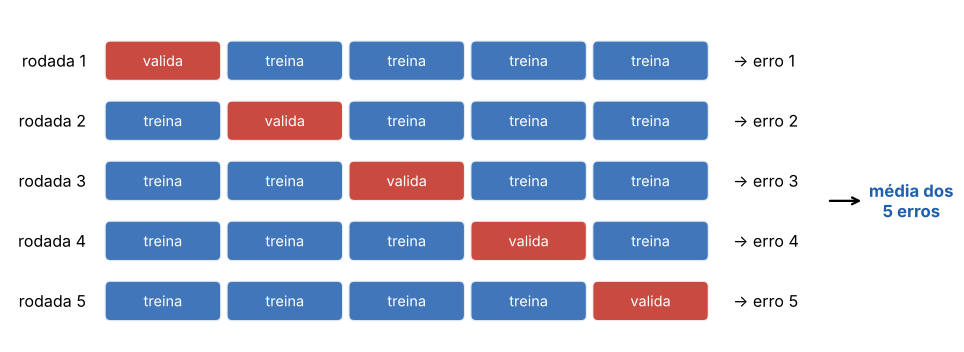

*Lembrete da aula 5: o treino é dividido em 5 partes. Em cada rodada, o modelo treina com 4 partes e é avaliado na parte que ficou de fora. A média dos 5 erros estima o erro em carros novos sem gastar o teste.*

**Lasso (penalidade L1).** Troca o quadrado pelo valor absoluto: `α · Σ|b_j|`. A diferença prática é grande: o Lasso leva coeficientes **exatamente a zero** e, assim, escolhe sozinho quais features usar. É uma **seleção de features** feita pelo próprio ajuste.

**Analogia.** O Ridge é uma mola em cada coeficiente: encolhe todos, sem zerar nenhum. O Lasso é um orçamento fixo para dividir entre as features: com orçamento curto, compensa gastar nas poucas que mais ajudam e deixar as outras com zero.

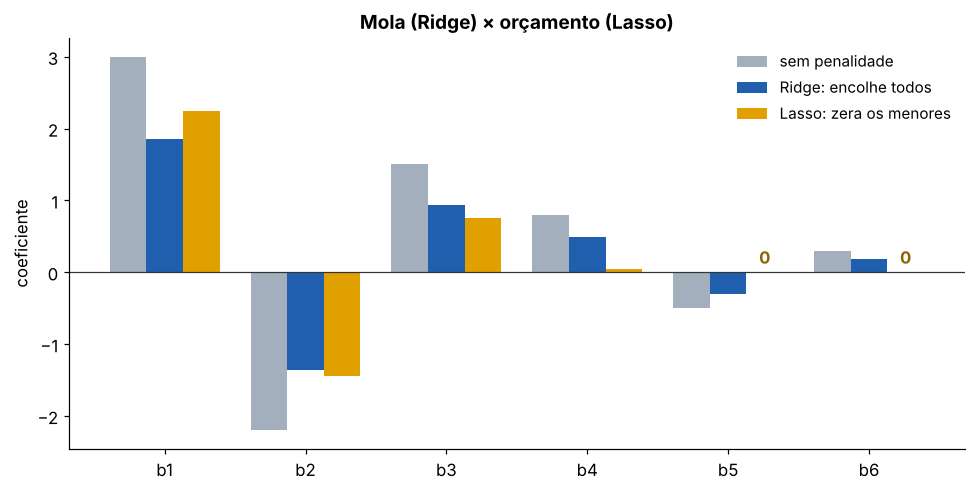

*Com coeficientes de exemplo: o Ridge (mola) encolhe todos os coeficientes, mas nenhum chega a zero; o Lasso (orçamento) encolhe e zera os menores, `b5` e `b6`.*

`LassoCV` testa uma lista de valores de `α` com validação cruzada **dentro do treino** e guarda o melhor em `alpha_`.

In [20]:
features = ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year']
X_tr, y_tr = treino[features], treino['mpg']
X_te, y_te = teste[features], teste['mpg']
dobras = KFold(5, shuffle=True, random_state=0)

def polinomio(grau, regressor=None):
    """Pipeline: potências de grau 1 até `grau` -> padronização -> regressor (LinearRegression por padrão)."""
    regressor = regressor if regressor is not None else LinearRegression()
    return make_pipeline(StandardScaler(), PolynomialFeatures(grau, include_bias=False),
                         StandardScaler(), regressor)

def rmse_cv(modelo):
    """RMSE da validação cruzada em 5 dobras, calculado só com o treino."""
    return np.sqrt(-cross_val_score(modelo, X_tr, y_tr, cv=dobras, scoring='neg_mean_squared_error').mean())

**Passo 4.1 · Linear × grau 4 sem penalidade.** Calculamos o erro de validação cruzada dos dois primeiros modelos com `rmse_cv`.

In [21]:
modelos = {
    'Linear (6 features)':   make_pipeline(StandardScaler(), LinearRegression()),
    'Grau 4 sem penalidade': polinomio(4, LinearRegression()),
}
cv = {nome: rmse_cv(m) for nome, m in modelos.items()}
for nome, erro in cv.items():
    print(f'{nome:24s} RMSE de validação cruzada: {erro:7.2f}')

Linear (6 features)      RMSE de validação cruzada:    3.57
Grau 4 sem penalidade    RMSE de validação cruzada:  543.35


**O que observar.** Com 209 coeficientes para 313 carros, o polinômio de grau 4 sem penalidade erra mais de cem vezes mais que a regressão linear: sobreajuste.

**Passo 4.2 · Grau 4 com Lasso.** Agora o mesmo polinômio com `LassoCV`, que testa os valores de `alphas_lasso` nas mesmas `dobras`. O erro de validação cruzada de cada `α` fica guardado no próprio modelo (`mse_path_`), por isso não é preciso chamar `rmse_cv`. Esta célula pode levar até um minuto.

In [22]:
alphas_lasso = np.logspace(-4, 0.5, 30)
lasso4 = polinomio(4, LassoCV(alphas=alphas_lasso, cv=dobras, max_iter=100000)).fit(X_tr, y_tr)
lasso = lasso4[-1]                                         # o último passo do pipeline é o LassoCV
erro_cv_lasso = np.sqrt(lasso.mse_path_.mean(axis=1))      # RMSE de validação cruzada para cada α
cv['Grau 4 + Lasso'] = erro_cv_lasso.min()
modelos['Grau 4 + Lasso'] = lasso4
print(f'α escolhido: {lasso.alpha_:.3f}')
print(f'RMSE de validação cruzada: {cv["Grau 4 + Lasso"]:.2f}  (linear: {cv["Linear (6 features)"]:.2f})')
print(f'coeficientes diferentes de zero: {np.sum(lasso.coef_ != 0)} de {lasso.coef_.size}')

α escolhido: 0.043
RMSE de validação cruzada: 2.75  (linear: 3.57)
coeficientes diferentes de zero: 33 de 209


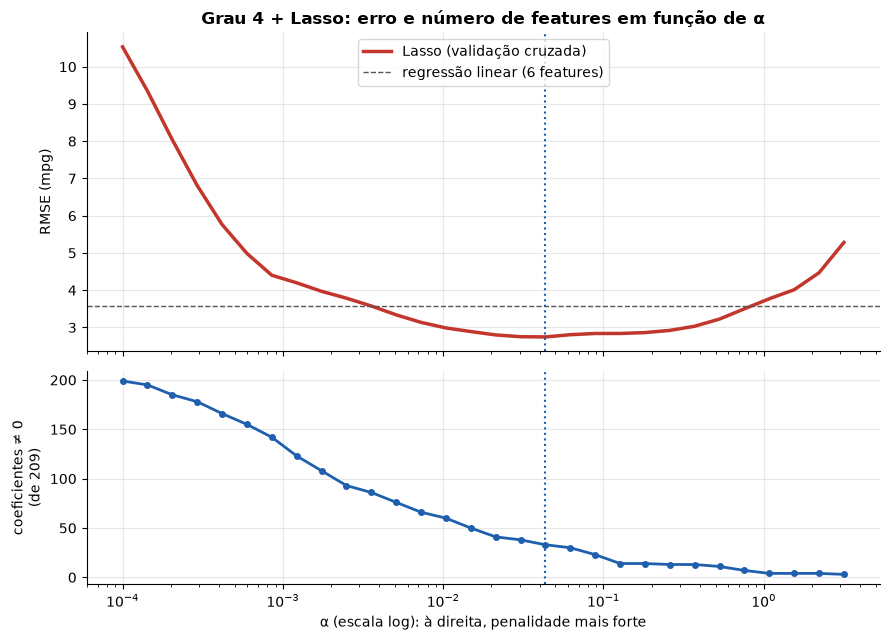

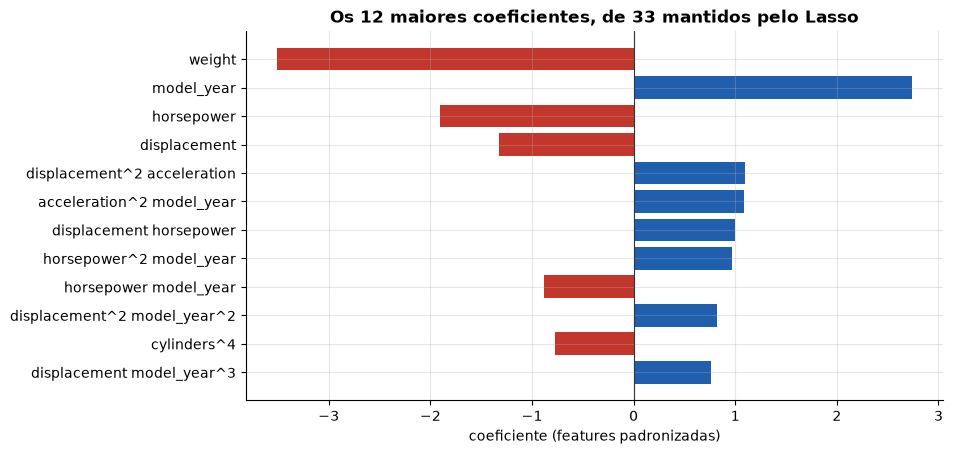

In [23]:
nomes = lasso4[1].get_feature_names_out(features)        # nomes das 209 features criadas
coef = pd.Series(lasso.coef_, index=nomes)
mantidas = coef[coef != 0]
n_nz = [np.sum(c != 0) for c in lasso.path(lasso4[:-1].transform(X_tr), y_tr - y_tr.mean(), alphas=lasso.alphas_)[1].T]

fig, eixos = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True, gridspec_kw={'height_ratios': [3, 2]})
eixos[0].semilogx(lasso.alphas_, erro_cv_lasso, color=VALID, lw=2.5, label='Lasso (validação cruzada)')
eixos[0].axhline(cv['Linear (6 features)'], color='#555', ls='--', lw=1, label='regressão linear (6 features)')
eixos[0].axvline(lasso.alpha_, color=MODELO, ls=':', lw=1.5)
eixos[0].set_ylabel('RMSE (mpg)')
eixos[0].set_title('Grau 4 + Lasso: erro e número de features em função de α')
eixos[0].legend(loc='upper center')
eixos[1].semilogx(lasso.alphas_, n_nz, 'o-', color=MODELO, lw=2, ms=4)
eixos[1].axvline(lasso.alpha_, color=MODELO, ls=':', lw=1.5)
eixos[1].set_ylabel('coeficientes ≠ 0\n(de 209)')
eixos[1].set_xlabel('α (escala log): à direita, penalidade mais forte')
plt.tight_layout()
plt.show()

mostrar = mantidas.reindex(mantidas.abs().sort_values().index).tail(12)
plt.figure(figsize=(9, 4.8))
plt.barh(mostrar.index, mostrar.values, color=[MODELO if v > 0 else VALID for v in mostrar.values])
plt.axvline(0, color='#333', lw=0.8)
plt.xlabel('coeficiente (features padronizadas)')
plt.title(f'Os 12 maiores coeficientes, de {len(mantidas)} mantidos pelo Lasso')
plt.show()

**Como ler os gráficos.** No primeiro, o eixo x é `α`: à esquerda, pouca penalidade; à direita, muita. Em cima, o erro de validação cruzada; embaixo, quantas das 209 features continuam no modelo. A linha pontilhada marca o `α` escolhido. No segundo, os maiores coeficientes que sobraram: azul aumenta o consumo previsto em mpg (carro mais econômico) e vermelho diminui. Nomes com espaço, como `weight model_year`, são produtos entre features; `weight^2` é um quadrado.

**O que observar.**

- O erro forma o **U** das etapas anteriores: à esquerda, o Lasso deixa quase todas as features e sobreajusta; à direita, zera quase todas e subajusta.
- No `α` escolhido, o modelo usa uma fração pequena das 209 features e tem erro **menor que o da regressão linear**. A regularização permitiu usar um modelo flexível sem pagar o preço do sobreajuste.
- Os maiores coeficientes são de features originais: `weight`, `horsepower` e `displacement` negativos (carros pesados, potentes e de motor grande gastam mais) e `model_year` positivo (carros mais novos são mais econômicos). Os demais são interações e potências que corrigem a curvatura.

### Passo 4.3 · Ridge × Lasso lado a lado

Para ver a diferença entre as duas penalidades com os dados reais, voltamos às **6 features originais**, padronizadas, e acompanhamos o que acontece com cada coeficiente quando `α` aumenta. Repare em quatro features que contam quase a mesma história: `cylinders`, `displacement`, `horsepower` e `weight` têm correlação entre 0,84 e 0,95 (carros grandes têm motores grandes, potentes e pesados).

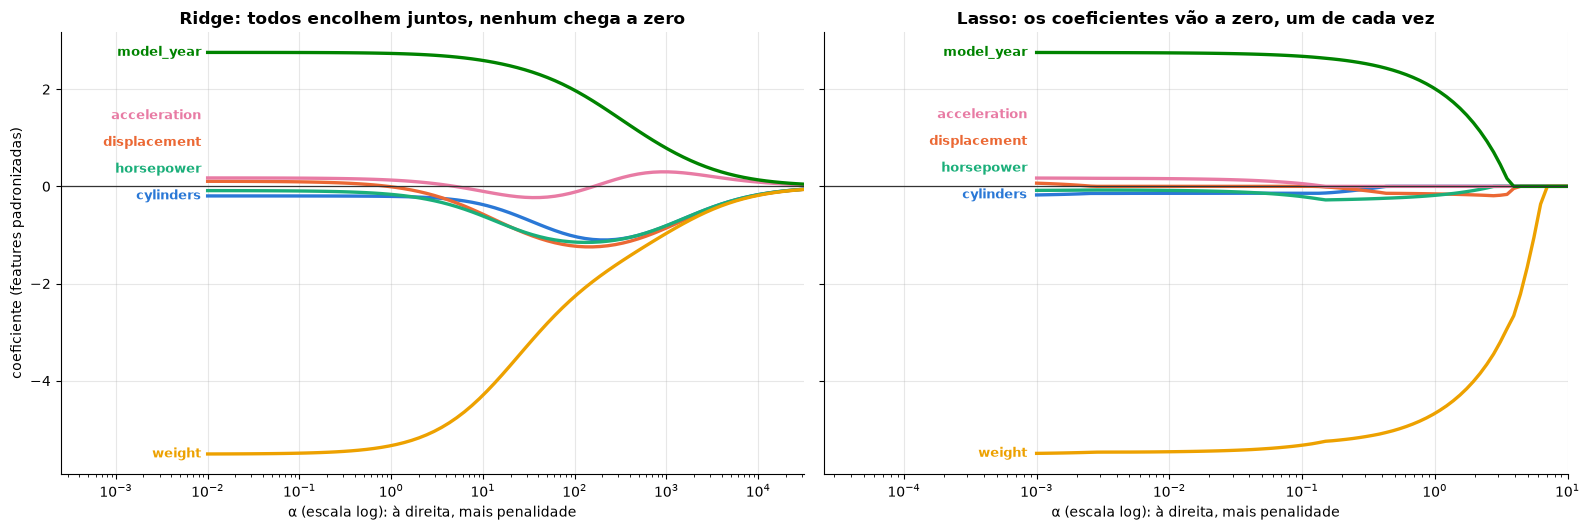

In [24]:
Z6 = StandardScaler().fit_transform(X_tr)                  # 6 features padronizadas
alphas_r = np.logspace(-2, 4.5, 80)
alphas_l = np.logspace(-3, 1, 80)
caminho_ridge = np.array([Ridge(alpha=a).fit(Z6, y_tr).coef_ for a in alphas_r])
caminho_lasso = np.array([Lasso(alpha=a, max_iter=100000).fit(Z6, y_tr).coef_ for a in alphas_l])
cores6 = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']

def rotulos(eixo, x, valores, passo=0.55):
    # rótulos à esquerda das curvas, afastados para não se sobreporem
    ordem = np.argsort(valores); pos = valores.astype(float).copy()
    for k in range(1, len(ordem)):
        pos[ordem[k]] = max(pos[ordem[k]], pos[ordem[k - 1]] + passo)
    for j, nome in enumerate(features):
        eixo.text(x, pos[j], nome, color=cores6[j], ha='right', va='center', fontsize=9.5, fontweight='bold')

fig, eixos = plt.subplots(1, 2, figsize=(16, 5.4), sharey=True)
for eixo, alphas, caminho, titulo in [(eixos[0], alphas_r, caminho_ridge, 'Ridge: todos encolhem juntos, nenhum chega a zero'),
                                      (eixos[1], alphas_l, caminho_lasso, 'Lasso: os coeficientes vão a zero, um de cada vez')]:
    for j in range(6):
        eixo.semilogx(alphas, caminho[:, j], color=cores6[j], lw=2.4)
    eixo.axhline(0, color='#333', lw=0.9)
    eixo.set_xlim(alphas[0] / 40, alphas[-1])
    rotulos(eixo, alphas[0] * 0.85, caminho[0])
    eixo.set_xlabel('α (escala log): à direita, mais penalidade')
    eixo.set_title(titulo)
eixos[0].set_ylabel('coeficiente (features padronizadas)')
plt.tight_layout()
plt.show()

**Como ler os gráficos.** Cada linha é o coeficiente de uma feature; o rótulo à esquerda indica a feature e o seu valor sem penalidade. Da esquerda para a direita, `α` aumenta. Os valores de `α` dos dois painéis não são comparáveis entre si (o Lasso do scikit-learn divide o erro por 2n e o Ridge não): compare a **forma** das curvas, e não a posição no eixo x.

**O que observar.**

- **Ridge:** as linhas se aproximam do zero aos poucos e só chegam perto dele com `α` muito grande. Mais interessante: `weight` começa em −5,5 e encolhe, enquanto `cylinders`, `displacement` e `horsepower`, que começavam perto de zero, **ganham peso**. O Ridge **divide** o efeito entre as features que contam a mesma história.
- **Lasso:** as linhas tocam o zero e ficam lá, uma de cada vez. `acceleration` e `cylinders` saem primeiro; `weight` e `model_year` são as últimas. Do grupo de features correlacionadas, o Lasso **concentra** o peso em `weight` e descarta as outras.

Para comparar diretamente, escolhemos uma penalidade intermediária para cada um e colocamos os coeficientes lado a lado com os da regressão sem penalidade.

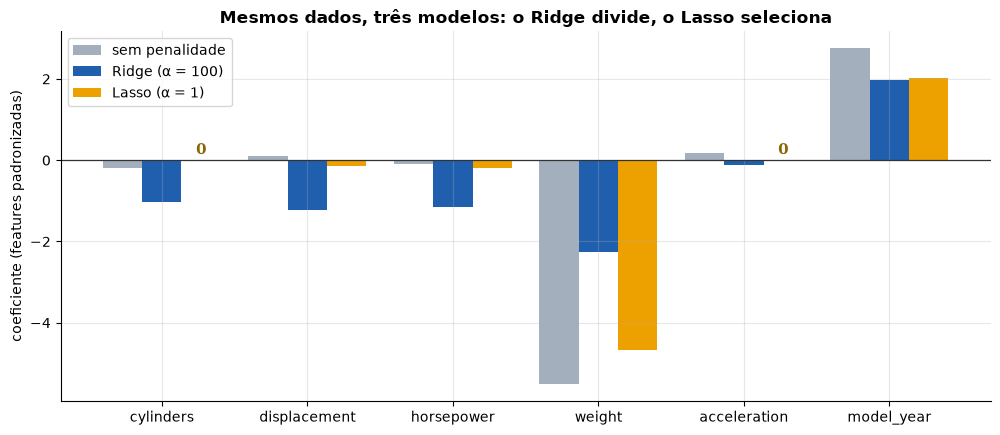

,sem penalidade,Ridge (α = 100),Lasso (α = 1)
cylinders,-0.20,-1.03,0.00
displacement,0.10,-1.23,-0.16
horsepower,-0.09,-1.15,-0.19
weight,-5.51,-2.27,-4.67
acceleration,0.17,-0.12,0.00
model_year,2.76,1.98,2.01


In [25]:
comparacao = pd.DataFrame({
    'sem penalidade': LinearRegression().fit(Z6, y_tr).coef_,
    'Ridge (α = 100)': Ridge(alpha=100).fit(Z6, y_tr).coef_,
    'Lasso (α = 1)': Lasso(alpha=1).fit(Z6, y_tr).coef_,
}, index=features)

x = np.arange(len(features)); larg = 0.27
plt.figure(figsize=(12, 4.8))
for k, (coluna, cor) in enumerate(zip(comparacao.columns, [CINZA, MODELO, '#eda100'])):
    plt.bar(x + (k - 1) * larg, comparacao[coluna], larg, color=cor, label=coluna)
for j, v in enumerate(comparacao['Lasso (α = 1)']):
    if v == 0:
        plt.text(j + larg, 0.15, '0', ha='center', fontsize=11, fontweight='bold', color='#8a6500')
plt.axhline(0, color='#333', lw=0.9)
plt.xticks(x, features)
plt.ylabel('coeficiente (features padronizadas)')
plt.title('Mesmos dados, três modelos: o Ridge divide, o Lasso seleciona')
plt.legend()
plt.show()
comparacao.round(2) + 0.0          # + 0.0 evita exibir -0.00

**O que observar.** Sem penalidade, quase todo o efeito está em `weight` e `model_year`, e os coeficientes de `cylinders`, `displacement` e `horsepower` ficam perto de zero com sinais trocados, um sintoma de features que disputam o mesmo efeito. O **Ridge** reparte o efeito do "tamanho do carro" entre as quatro features correlacionadas: `cylinders`, `displacement` e `horsepower` passam a ter coeficientes perto de −1, e `weight` cai de −5,5 para −2,3. O **Lasso** zera `cylinders` e `acceleration` e mantém praticamente tudo em `weight` e `model_year`: um modelo com menos features, mais fácil de explicar.

**Resumo da comparação.**

| | Ridge (L2) | Lasso (L1) |
|---|---|---|
| Penalidade | soma dos quadrados dos coeficientes | soma dos valores absolutos |
| Coeficientes | encolhem, nenhum vira zero | encolhem e alguns viram zero |
| Features correlacionadas | divide o peso entre elas | escolhe uma e descarta as outras |
| Bom quando | muitas features ajudam um pouco cada | poucas features importam; quer-se um modelo simples |

**Para discutir.** O Ridge também resolveria o sobreajuste do grau 4, mas manteria os 209 coeficientes. Em que situação você preferiria o Lasso? E o Ridge?

> **Resposta:** Lasso quando queremos um modelo mais simples de explicar, ou quando suspeitamos que muitas features não ajudam. Ridge quando muitas features contribuem um pouco cada uma, ou quando há grupos de features correlacionadas: nesse caso o Lasso escolhe uma delas de forma instável, e o Ridge divide o peso entre todas.

### Passo 4.4 · Avaliação final no teste

Todas as escolhas foram feitas sem olhar para o teste: o grau, `α` e o tipo de penalidade. Agora, e só agora, medimos o erro no conjunto de teste, **uma única vez**. Incluímos também o grau 4 com Ridge, com `α` escolhido por `RidgeCV`.

Treinamos cada modelo no treino completo e calculamos o RMSE no teste.

In [26]:
modelos['Grau 4 + Ridge'] = polinomio(4, RidgeCV(alphas=np.logspace(-3, 3, 40)))
final = {}
for nome, m in modelos.items():
    m.fit(X_tr, y_tr)
    final[nome] = {'RMSE teste (mpg)': rmse(y_te, m.predict(X_te)),
                   'coeficientes ≠ 0': int(np.sum(m[-1].coef_ != 0))}
tabela = pd.DataFrame(final).T
tabela['RMSE teste (mpg)'] = tabela['RMSE teste (mpg)'].round(2)
tabela['coeficientes ≠ 0'] = tabela['coeficientes ≠ 0'].astype(int)
tabela

,RMSE teste (mpg),coeficientes ≠ 0
Linear (6 features),3.24,6
Grau 4 sem penalidade,15.98,209
Grau 4 + Lasso,2.39,33
Grau 4 + Ridge,2.35,209


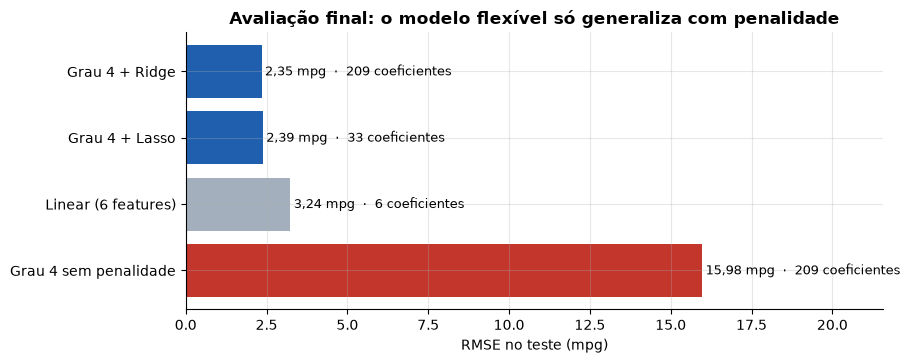

In [27]:
ordem = tabela.sort_values('RMSE teste (mpg)', ascending=False)
plt.figure(figsize=(9, 3.6))
plt.barh(ordem.index, ordem['RMSE teste (mpg)'],
         color=[VALID if 'sem' in n else MODELO if ('Lasso' in n or 'Ridge' in n) else CINZA for n in ordem.index])
for i, (v, nz) in enumerate(zip(ordem['RMSE teste (mpg)'], ordem['coeficientes ≠ 0'])):
    plt.text(v + 0.1, i, f'{v:.2f}'.replace('.', ',') + f' mpg  ·  {nz} coeficientes', va='center', fontsize=9)
plt.xlim(0, ordem['RMSE teste (mpg)'].max() * 1.35)
plt.xlabel('RMSE no teste (mpg)')
plt.title('Avaliação final: o modelo flexível só generaliza com penalidade')
plt.show()

**O que observar.** O teste confirma o que a validação cruzada indicou. O polinômio de grau 4 sem penalidade é, de longe, o pior modelo. Com Lasso ou Ridge, o mesmo polinômio erra menos que a regressão linear. O Lasso chega lá com uma fração dos coeficientes; o Ridge mantém os 209, todos pequenos.

---
## Etapa 5 · Modelos lineares generalizados (9 min)

Até aqui, tudo foi regressão: o alvo era um número (mpg). Mas a regressão logística da aula 3 também começa com a mesma conta, `z = a + b₁x₁ + b₂x₂ + …`. A diferença está no que fazemos com `z` depois:

- na **regressão linear**, `z` já é a previsão (a ligação é a identidade);
- na **regressão logística**, `z` passa pela **sigmoide** e vira uma probabilidade entre 0 e 1.

Essa família de modelos, em que um **preditor linear** passa por uma **função de ligação** que o leva para a escala do alvo, se chama **modelos lineares generalizados** (*GLM*, do inglês *generalized linear models*). E como todos aprendem coeficientes `b`, a ideia desta aula vale para todos: **sobreajuste aparece como coeficientes grandes, e a penalidade os controla**.

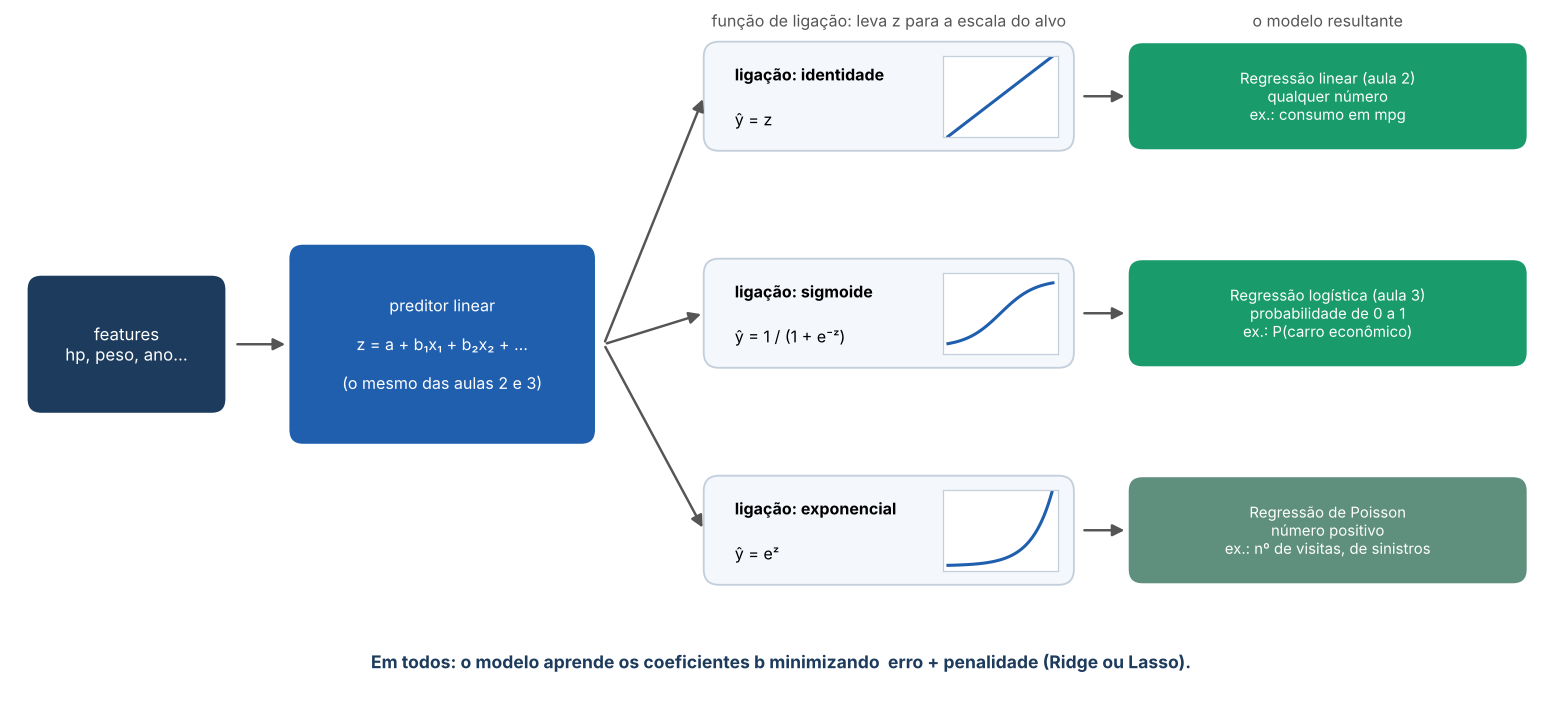

*A receita comum. Os carros entram como features, viram um número `z` pela mesma combinação linear das aulas 2 e 3, e a função de ligação escolhe a "língua" da resposta: um número qualquer, uma probabilidade ou uma contagem positiva. É como uma mesma massa de pão que vira pão de forma, pizza ou rosca dependendo da forma em que é assada: os ingredientes (coeficientes) são aprendidos do mesmo jeito.*

### Passo 5.1 · A mesma feature, duas ligações

Vamos transformar o problema dos carros em uma classificação: um carro é **econômico** se faz mais de 25 milhas por galão (cerca de 10,6 km/l). Cerca de 40% dos carros da base passam nesse critério.

Usando só a potência, treinamos nos 313 carros de treino:

- uma **regressão linear** para prever o consumo em mpg (ligação identidade);
- uma **regressão logística** para prever a probabilidade de o carro ser econômico (ligação sigmoide).

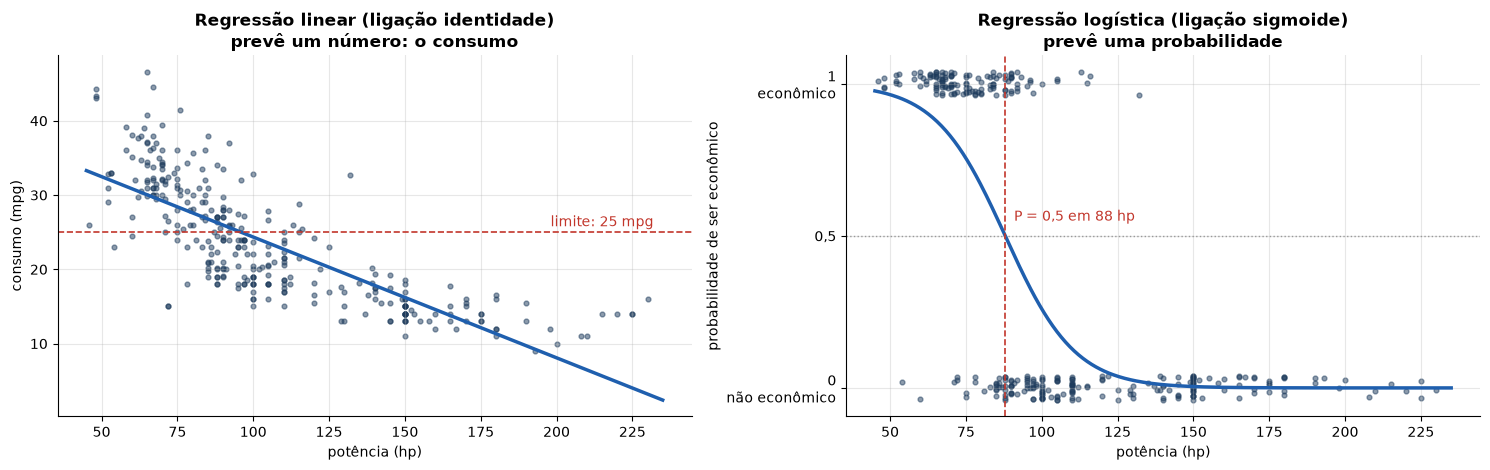

In [28]:
LIMITE = 25                                        # mpg; acima disso, o carro é "econômico"
economico_tr = (treino['mpg'] > LIMITE).astype(int)

lin = polinomio(1).fit(treino[['horsepower']], treino['mpg'])
modelo_log = polinomio(1, LogisticRegression()).fit(treino[['horsepower']], economico_tr)
hp_meio = grade['horsepower'][np.argmin(np.abs(modelo_log.predict_proba(grade)[:, 1] - 0.5))]

fig, eixos = plt.subplots(1, 2, figsize=(15, 4.8))
eixos[0].scatter(treino['horsepower'], treino['mpg'], s=12, color=TREINO, alpha=0.5)
eixos[0].plot(grade['horsepower'], lin.predict(grade), color=MODELO, lw=2.5)
eixos[0].axhline(LIMITE, color=VALID, ls='--', lw=1.2)
eixos[0].text(232, LIMITE + 0.8, 'limite: 25 mpg', ha='right', color=VALID)
eixos[0].set_xlabel('potência (hp)'); eixos[0].set_ylabel('consumo (mpg)')
eixos[0].set_title('Regressão linear (ligação identidade)\nprevê um número: o consumo')

jitter = np.random.default_rng(0).uniform(-0.04, 0.04, len(treino))
eixos[1].scatter(treino['horsepower'], economico_tr + jitter, s=12, color=TREINO, alpha=0.5)
eixos[1].plot(grade['horsepower'], modelo_log.predict_proba(grade)[:, 1], color=MODELO, lw=2.5)
eixos[1].axhline(0.5, color='#999', ls=':', lw=1)
eixos[1].axvline(hp_meio, color=VALID, ls='--', lw=1.2)
eixos[1].text(hp_meio + 3, 0.55, f'P = 0,5 em {hp_meio:.0f} hp', color=VALID)
eixos[1].set_yticks([0, 0.5, 1], ['0\nnão econômico', '0,5', '1\neconômico'])
eixos[1].set_xlabel('potência (hp)'); eixos[1].set_ylabel('probabilidade de ser econômico')
eixos[1].set_title('Regressão logística (ligação sigmoide)\nprevê uma probabilidade')
plt.tight_layout()
plt.show()

**Como ler os gráficos.** À esquerda, cada ponto é um carro com o seu consumo real; à direita, cada ponto está em 1 (econômico) ou em 0 (não econômico), com um pequeno deslocamento vertical para os pontos não se sobreporem. A linha azul é o modelo.

**O que observar.** Os dois modelos usam a mesma feature e o mesmo preditor linear `a + b·hp`; só a ligação muda. A reta pode prever qualquer número: se a potência continuasse crescendo, ela chegaria a consumos negativos. A sigmoide nunca sai do intervalo de 0 a 1: carros fracos têm probabilidade alta de serem econômicos, carros potentes, baixa. A fronteira de decisão (P = 0,5, em 88 hp) fica um pouco antes do ponto em que a reta da esquerda cruza o limite de 25 mpg, perto de 100 hp: os dois modelos contam a mesma história em escalas diferentes.

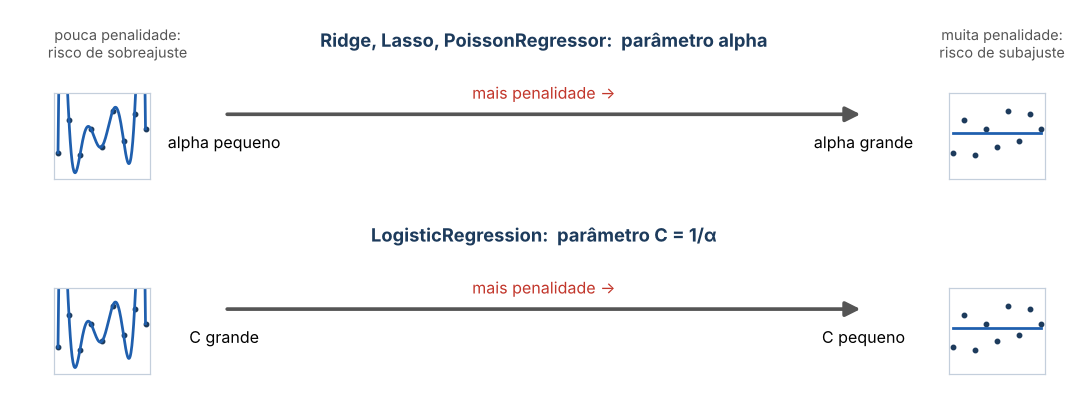

*A penalidade existe nos dois modelos, mas o botão gira em sentidos opostos. No Ridge e no Lasso, aumentar `alpha` aumenta a penalidade. Na `LogisticRegression`, o parâmetro é `C = 1/α`: **diminuir** `C` aumenta a penalidade. Um detalhe que costuma surpreender: a `LogisticRegression()` da aula 3 já vinha com penalidade Ridge (L2) e `C = 1` por padrão.*

### Passo 5.2 · Sobreajuste e regularização na logística

Repetimos o experimento da Etapa 1, agora para classificar: o polinômio de grau 12 na potência, treinado nos mesmos 20 carros da amostra, com e sem penalidade. Para "desligar" a penalidade, usamos um `C` enorme (`10⁶`).

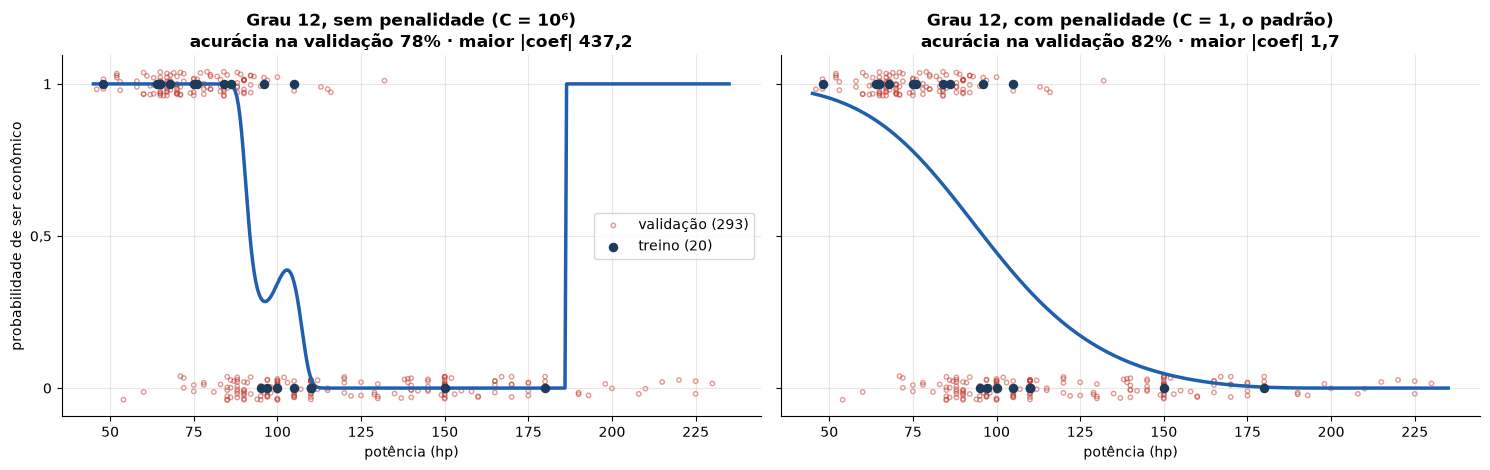

In [29]:
eco_am = (y_am > LIMITE).astype(int)
eco_val = (y_val > LIMITE).astype(int)

fig, eixos = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for eixo, (C_valor, nome) in zip(eixos, [(1e6, 'sem penalidade (C = 10⁶)'), (1.0, 'com penalidade (C = 1, o padrão)')]):
    m = polinomio(12, LogisticRegression(C=C_valor, max_iter=100000)).fit(X_am, eco_am)
    acc = (m.predict(X_val) == eco_val).mean()
    maior = np.abs(m[-1].coef_).max()
    jv = np.random.default_rng(1).uniform(-0.04, 0.04, len(X_val))
    eixo.scatter(X_val['horsepower'], eco_val + jv, s=10, facecolors='none', edgecolors=VALID, alpha=0.5, label='validação (293)')
    eixo.scatter(X_am['horsepower'], eco_am, s=34, color=TREINO, zorder=3, label='treino (20)')
    eixo.plot(grade['horsepower'], m.predict_proba(grade)[:, 1], color=MODELO, lw=2.5)
    eixo.set_title(f'Grau 12, {nome}\nacurácia na validação {acc:.0%} · maior |coef| {fmt(maior)}')
    eixo.set_xlabel('potência (hp)')
eixos[0].set_ylabel('probabilidade de ser econômico')
eixos[0].set_yticks([0, 0.5, 1], ['0', '0,5', '1'])
eixos[0].legend(loc='center right')
plt.tight_layout()
plt.show()

**O que observar.** É a mesma história da regressão, agora em classificação. Sem penalidade, a probabilidade sobe e desce para acertar os 20 carros de treino: um carro de muita potência chega a ser considerado econômico, e os coeficientes ficam na casa das centenas. Com `C = 1`, os coeficientes ficam pequenos, a curva volta a ter a forma de uma sigmoide e a acurácia na validação melhora.

**Outros membros da família.** O scikit-learn também traz `PoissonRegressor`, para contagens (como o número de visitas de um cliente), e `GammaRegressor`, para valores sempre positivos (como o valor de um sinistro). Os dois seguem a mesma receita e têm um parâmetro `alpha` de penalidade Ridge. Não vamos treiná-los nesta aula; o importante é reconhecer que a regularização vista hoje vale para toda a família.

**Para discutir.** Se quiséssemos prever quantas vezes um carro vai à oficina por ano, que ligação usaríamos? E o que faríamos se o modelo sobreajustasse?

---
## Etapa 6 · Fechamento (3 min)

### Resumo da aula

| Situação | Erro de treino | Erro de validação | Diagnóstico | O que fazer |
|---|---|---|---|---|
| Modelo rígido demais | alto | alto | subajuste | modelo mais flexível, mais features, menos penalidade |
| Modelo adequado | baixo | baixo e próximo do treino | equilíbrio | manter |
| Modelo flexível demais | muito baixo | alto | sobreajuste | regularização (aumentar `α`), mais dados, modelo mais simples |

| Ferramenta | Penalidade | Efeito nos coeficientes | Parâmetro no scikit-learn |
|---|---|---|---|
| `Ridge` | L2: soma dos quadrados | encolhe todos, nenhum vira zero | `alpha` ↑ = mais penalidade |
| `Lasso` | L1: soma dos valores absolutos | encolhe e zera alguns: seleção de features | `alpha` ↑ = mais penalidade |
| `LogisticRegression` | L2 por padrão | o mesmo do Ridge, para probabilidades | `C` ↓ = mais penalidade |
| `PoissonRegressor`, `GammaRegressor` | L2 | o mesmo do Ridge, para contagens e valores positivos | `alpha` ↑ = mais penalidade |